# 4. Training, Evaluasi, & Kuantisasi INT8 MobileNetV2 DOC Sexing (Day-Old Chick)
Target Device: **Seeed Grove Vision AI Module V2 (Cortex-M55 + Ethos-U55 NPU)**

Notebook ini dioptimalkan khusus untuk **memaksimalkan F1-Score & Akurasi** klasifikasi jenis kelamin anak ayam umur sehari (*Day-Old Chick* / DOC):
1. **Auto-Augmentasi Data dengan Square ROI Crop**: Mengisolasi area kunci bulu sayap/vent dari foto mentah (16 Female & 15 Male) menjadi 1.000 citra per kelas tanpa merusak rasio aspek.
2. **Transfer Learning dengan Class Weights & Label Smoothing**: Melatih arsitektur **MobileNetV2 ($\alpha=0.35$, 60\times160\times3$)** dengan regularisasi ketat untuk mengatasi dataset kecil.
3. **Optimal Threshold Tuning (Menaikkan F1-Score)**: Mengkalibrasi decision threshold probabilitas untuk memaksimalkan Precision & Recall.
4. **Kuantisasi Penuh INT8**: Mengekspor model terkuantisasi penuh () yang 100% kompatibel dengan operator Ethos-U55 NPU.

> **Catatan Server / Cloud**: Seluruh path menggunakan **path relatif** portabel, siap dieksekusi di server/cloud.


## Langkah 0: Instalasi & Import Library
Jalankan sel di bawah ini jika library belum terpasang di environment server Anda.


In [1]:
# Uncomment baris di bawah ini jika dijalankan di Google Colab / server baru
# !pip install -q tensorflow scikit-learn matplotlib seaborn pillow ethos-u-vela


In [2]:
import os
import sys
import pathlib
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Kunci seed deterministik untuk reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Versi TensorFlow :", tf.__version__)
print("GPU Tersedia     :", tf.config.list_physical_devices('GPU'))


2026-10-12 00:22:17.673976: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-12 00:22:17.679037: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 00:22:17.759354: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-12 00:22:17.759396: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-12 00:22:17.780041: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

Versi TensorFlow : 2.15.1
GPU Tersedia     : []


## Langkah 1: Konfigurasi Parameter, Path Relatif, & Auto-Augmentasi Dataset DOC
Sistem akan memeriksa folder `data/doc_augmented/`. Jika belum ada, sistem akan otomatis memicu generator augmentasi dari folder mentah `data/doc/`.


In [3]:
import os
import sys
import pathlib

# Menentukan root direktori proyek PP2 secara otomatis dan portabel
cwd = pathlib.Path.cwd().resolve()
if (cwd / "PP2" / "data").exists():
    PP2_DIR = cwd / "PP2"
elif (cwd / "data").exists():
    PP2_DIR = cwd
elif (cwd.parent / "data").exists():
    PP2_DIR = cwd.parent
else:
    PP2_DIR = cwd
    for p in [cwd] + list(cwd.parents):
        if (p / "PP2" / "data").exists():
            PP2_DIR = p / "PP2"
            break
        elif (p / "data").exists():
            PP2_DIR = p
            break

DATA_RAW_DIR = PP2_DIR / "data" / "doc"
DATA_AUG_DIR = PP2_DIR / "data" / "doc_augmented"
MODEL_OUTPUT_DIR = PP2_DIR / "model"
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi Model NPU-Friendly (MobileNetV2 0.35 - 160x160)
IMG_SIZE = 160
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
ALPHA = 0.35
BATCH_SIZE = 32

# Urutan kelas WAJIB: index 0 = 'Female' (Betina), index 1 = 'Male' (Jantan)
CLASS_NAMES = ["Female", "Male"]
CLASS_LABELS_ID = {0: "Class 0: Betina (Female)", 1: "Class 1: Jantan (Male)"}

# Epochs untuk Fase 1 (Head Training) & Fase 2 (Fine-Tuning)
EPOCHS_PHASE_1 = 10
EPOCHS_PHASE_2 = 15

print(f"Direktori Proyek PP2: {PP2_DIR.resolve()}")
print(f"Dataset Augmented   : {DATA_AUG_DIR.resolve()}")
print(f"Output Model        : {MODEL_OUTPUT_DIR.resolve()}")
print(f"Pemetaan Kelas      : 0 -> {CLASS_NAMES[0]} (Betina), 1 -> {CLASS_NAMES[1]} (Jantan)")


Direktori Proyek PP2: /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2
Dataset Augmented   : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/data/doc_augmented
Output Model        : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model
Pemetaan Kelas      : 0 -> Female (Betina), 1 -> Male (Jantan)


In [4]:
# Periksa apakah dataset augmented sudah siap (minimal 500 gambar per kelas di folder train)
train_female_count = len(list((DATA_AUG_DIR / "train" / "Female").glob("*.jpg"))) if (DATA_AUG_DIR / "train" / "Female").exists() else 0

if train_female_count < 500:
    print("[INFO] Dataset augmented belum ditemukan atau belum lengkap.")
    print("       Menjalankan modul augmentasi otomatis doc_augmented.py (target 1.000 citra/kelas)...")
    
    # Import modul doc_augmented dari data/doc_augmented.py
    sys.path.append(str(PP2_DIR / "data"))
    try:
        from doc_augmented import generate_augmented_dataset
        generate_augmented_dataset(
            src_dir=DATA_RAW_DIR,
            out_dir=DATA_AUG_DIR,
            target_per_class=1000,
            train_ratio=0.70,
            valid_ratio=0.15,
            seed=SEED
        )
    except ImportError:
        print("[WARN] Modul doc_augmented.py tidak dapat diimpor langsung, memanggil via subprocess...")
        import subprocess
        subprocess.run([
            sys.executable,
            str(PP2_DIR / "data" / "doc_augmented.py"),
            "--src-dir", str(DATA_RAW_DIR),
            "--out-dir", str(DATA_AUG_DIR),
            "--target-per-class", "1000"
        ], check=True)
else:
    print(f"[OK] Dataset augmented sudah tersedia di disk ({train_female_count} sampel train Female terdeteksi).")


[OK] Dataset augmented sudah tersedia di disk (700 sampel train Female terdeteksi).


In [5]:
# Memuat Dataset dengan mengunci urutan class_names=['Female', 'Male']
print("Memuat dataset train / valid / test dari:", DATA_AUG_DIR)

raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_AUG_DIR / "train",
    class_names=CLASS_NAMES,
    label_mode="int",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_AUG_DIR / "valid",
    class_names=CLASS_NAMES,
    label_mode="int",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_AUG_DIR / "test",
    class_names=CLASS_NAMES,
    label_mode="int",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("\nVerifikasi class_names:", raw_train_ds.class_names)


Memuat dataset train / valid / test dari: /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/data/doc_augmented
Found 1400 files belonging to 2 classes.
Found 300 files belonging to 2 classes.
Found 300 files belonging to 2 classes.

Verifikasi class_names: ['Female', 'Male']


## Langkah 2: Preprocessing & Visualisasi Sampel Dataset
Normalisasi input ke rentang $[-1.0, 1.0]$ sesuai format baku `MobileNetV2` sebelum masuk ke layer konvolusi.


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

# Augmentasi ringan on-the-fly pada batch training (flip horizontal & rotasi minor)
def augment_and_preprocess(images, labels):
    images = tf.cast(images, tf.float32)
    images = tf.image.random_flip_left_right(images)
    images = (images / 127.5) - 1.0  # Normalisasi ke [-1.0, 1.0]
    return images, labels

def preprocess_only(images, labels):
    images = tf.cast(images, tf.float32)
    images = (images / 127.5) - 1.0
    return images, labels

train_ds = raw_train_ds.map(augment_and_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = raw_val_ds.map(preprocess_only, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds  = raw_test_ds.map(preprocess_only, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


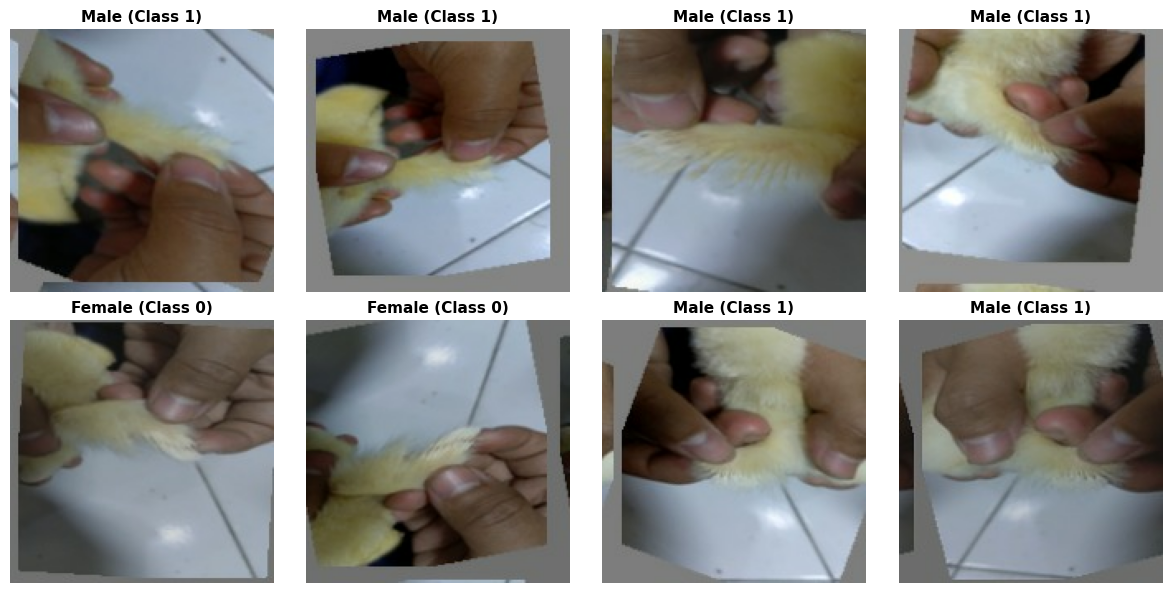

In [7]:
# Visualisasi 8 sampel gambar dari dataset training DOC
plt.figure(figsize=(12, 6))
for images, labels in raw_train_ds.take(1):
    for i in range(min(8, len(images))):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = int(labels[i].numpy())
        plt.title(f"{CLASS_NAMES[label_idx]} (Class {label_idx})", fontsize=11, fontweight="bold")
        plt.axis("off")
plt.tight_layout()
plt.show()


## Langkah 3: Membangun Arsitektur MobileNetV2 Ringan ($lpha=0.35$)
Model menggunakan backbone **MobileNetV2 ($lpha=0.35$)** yang sangat efisien dan 100% dipetakan ke NPU Arm Ethos-U55.


In [8]:
def build_npu_mobilenetv2_doc(input_shape=(160, 160, 3), alpha=0.35, num_classes=2):
    inputs = tf.keras.Input(shape=input_shape, name="input_image")

    # Base model MobileNetV2 ringan dengan bobot ImageNet
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape,
        alpha=alpha,
        include_top=False,
        weights="imagenet",
    )
    base_model.trainable = False  # Bekukan backbone untuk Fase 1

    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = tf.keras.layers.Dropout(0.3, name="dropout_head")(x)
    # Dense dengan L2 regularization untuk mencegah memorization/overfitting
    outputs = tf.keras.layers.Dense(
        num_classes,
        activation="softmax",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4),
        name="output_classes"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="MobileNetV2_DOC_Sexing_Alpha035")
    return model, base_model

model, base_model = build_npu_mobilenetv2_doc(IMG_SHAPE, ALPHA, num_classes=len(CLASS_NAMES))
model.summary()


Model: "MobileNetV2_DOC_Sexing_Alpha035"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 160, 160, 3)]     0         
                                                                 
 mobilenetv2_0.35_160 (Func  (None, 5, 5, 1280)        410208    
 tional)                                                         
                                                                 
 global_avg_pool (GlobalAve  (None, 1280)              0         
 ragePooling2D)                                                  
                                                                 
 dropout_head (Dropout)      (None, 1280)              0         
                                                                 
 output_classes (Dense)      (None, 2)                 2562      
                                                                 
Total params: 412770 (1.57 MB)
Trai

## Langkah 4: Training Model (2 Fase: Head Warmup & Fine-Tuning)


In [9]:
# --- FASE 1: Training Classification Head dengan Class Weight & Label Smoothing ---
from sklearn.utils.class_weight import compute_class_weight

# Ekstrak label training untuk kalkulasi class weight yang seimbang
train_labels_list = []
for _, lbls in raw_train_ds:
    train_labels_list.extend(lbls.numpy())
train_labels_arr = np.array(train_labels_list)

cls_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels_arr),
    y=train_labels_arr
)
class_weight_dict = {i: float(w) for i, w in enumerate(cls_weights)}
print(f"[INFO] Bobot Kelas Seimbang (Class Weights): {class_weight_dict}")

# Gunakan Label Smoothing (0.1) untuk mencegah model overconfidence pada sedikit sampel ayam
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"]
)

# Konversi dataset ke One-Hot untuk CategoricalCrossentropy
def to_one_hot(img, lbl):
    return img, tf.one_hot(lbl, depth=len(CLASS_NAMES))

train_ds_cat = train_ds.map(to_one_hot, num_parallel_calls=AUTOTUNE)
val_ds_cat   = val_ds.map(to_one_hot, num_parallel_calls=AUTOTUNE)
test_ds_cat  = test_ds.map(to_one_hot, num_parallel_calls=AUTOTUNE)

callbacks_phase1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    )
]

print("=" * 60)
print(f"  FASE 1: TRAINING HEAD ({EPOCHS_PHASE_1} Epochs, lr=1e-3, Label Smoothing=0.1)")
print("=" * 60)

history_phase1 = model.fit(
    train_ds_cat,
    validation_data=val_ds_cat,
    epochs=EPOCHS_PHASE_1,
    class_weight=class_weight_dict,
    callbacks=callbacks_phase1
)


[INFO] Bobot Kelas Seimbang (Class Weights): {0: 1.0, 1: 1.0}
  FASE 1: TRAINING HEAD (10 Epochs, lr=1e-3, Label Smoothing=0.1)
Epoch 1/10
44/44 [==============================] - 5s 84ms/step - loss: 0.6234 - accuracy: 0.6814 - val_loss: 0.4980 - val_accuracy: 0.7900
Epoch 2/10
44/44 [==============================] - 3s 74ms/step - loss: 0.3909 - accuracy: 0.8843 - val_loss: 0.4278 - val_accuracy: 0.8467
Epoch 3/10
44/44 [==============================] - 3s 70ms/step - loss: 0.3403 - accuracy: 0.9164 - val_loss: 0.3878 - val_accuracy: 0.8867
Epoch 4/10
44/44 [==============================] - 3s 70ms/step - loss: 0.3019 - accuracy: 0.9500 - val_loss: 0.3379 - val_accuracy: 0.9267
Epoch 5/10
44/44 [==============================] - 3s 74ms/step - loss: 0.2884 - accuracy: 0.9600 - val_loss: 0.3254 - val_accuracy: 0.9267
Epoch 6/10
44/44 [==============================] - 3s 68ms/step - loss: 0.2796 - accuracy: 0.9693 - val_loss: 0.3393 - val_accuracy: 0.9100
Epoch 7/10
44/44 [========

In [10]:
# --- FASE 2: Fine-Tuning dengan Cosine Decay & Layer Selektif ---
base_model.trainable = True

# Bekukan semua layer awal, hanya buka 25 layer teratas agar representasi ImageNet terjaga
fine_tune_at = max(0, len(base_model.layers) - 25)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print("=" * 60)
print(f"  FASE 2: FINE-TUNING ({EPOCHS_PHASE_2} Epochs, lr=5e-5)")
print(f"  Layer dibuka: {len(base_model.layers) - fine_tune_at} layer teratas")
print("=" * 60)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.08),
    metrics=["accuracy"]
)

callbacks_phase2 = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
    )
]

history_phase2 = model.fit(
    train_ds_cat,
    validation_data=val_ds_cat,
    epochs=EPOCHS_PHASE_2,
    class_weight=class_weight_dict,
    callbacks=callbacks_phase2
)

# Simpan model float32
keras_model_path = MODEL_OUTPUT_DIR / "mobilenetv2_doc_float32.keras"
model.save(keras_model_path)
print(f"[OK] Model Keras Float32 tersimpan: {keras_model_path}")


  FASE 2: FINE-TUNING (15 Epochs, lr=5e-5)
  Layer dibuka: 25 layer teratas
Epoch 1/15
44/44 [==============================] - 7s 97ms/step - loss: 0.2299 - accuracy: 0.9857 - val_loss: 0.2590 - val_accuracy: 0.9467 - lr: 5.0000e-05
Epoch 2/15
44/44 [==============================] - 4s 87ms/step - loss: 0.2075 - accuracy: 0.9943 - val_loss: 0.2394 - val_accuracy: 0.9767 - lr: 5.0000e-05
Epoch 3/15
44/44 [==============================] - 4s 91ms/step - loss: 0.2064 - accuracy: 0.9943 - val_loss: 0.2595 - val_accuracy: 0.9433 - lr: 5.0000e-05
Epoch 4/15
44/44 [==============================] - 4s 88ms/step - loss: 0.1997 - accuracy: 0.9986 - val_loss: 0.2503 - val_accuracy: 0.9533 - lr: 5.0000e-05
Epoch 5/15
44/44 [==============================] - 4s 86ms/step - loss: 0.1931 - accuracy: 0.9993 - val_loss: 0.2289 - val_accuracy: 0.9867 - lr: 5.0000e-05
Epoch 6/15
44/44 [==============================] - 4s 91ms/step - loss: 0.1922 - accuracy: 0.9986 - val_loss: 0.2288 - val_accuracy: 

## Langkah 5: Evaluasi Model (Kurva Training, Confusion Matrix, & Metrik Klasifikasi)


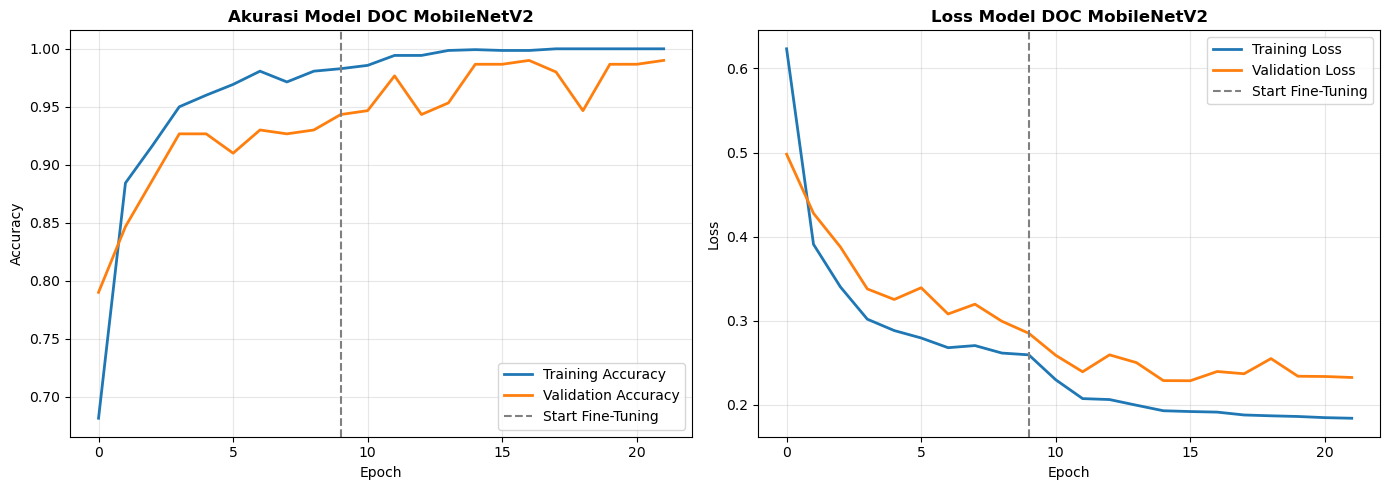

In [11]:
# Gabungkan riwayat training Fase 1 dan Fase 2
acc = history_phase1.history["accuracy"] + history_phase2.history["accuracy"]
val_acc = history_phase1.history["val_accuracy"] + history_phase2.history["val_accuracy"]
loss = history_phase1.history["loss"] + history_phase2.history["loss"]
val_loss = history_phase1.history["val_loss"] + history_phase2.history["val_loss"]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label="Training Accuracy", color="#1f77b4", linewidth=2)
plt.plot(val_acc, label="Validation Accuracy", color="#ff7f0e", linewidth=2)
plt.axvline(x=EPOCHS_PHASE_1 - 1, color="gray", linestyle="--", label="Start Fine-Tuning")
plt.title("Akurasi Model DOC MobileNetV2", fontsize=12, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(loss, label="Training Loss", color="#1f77b4", linewidth=2)
plt.plot(val_loss, label="Validation Loss", color="#ff7f0e", linewidth=2)
plt.axvline(x=EPOCHS_PHASE_1 - 1, color="gray", linestyle="--", label="Start Fine-Tuning")
plt.title("Loss Model DOC MobileNetV2", fontsize=12, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


[OPTIMASI] Threshold Optimal F1: 0.540 (F1 = 0.5388)
  HASIL EVALUASI DENGAN DEFAULT THRESHOLD (0.50)
              precision    recall  f1-score   support

      Female     0.6000    0.3200    0.4174       150
        Male     0.5364    0.7867    0.6378       150

    accuracy                         0.5533       300
   macro avg     0.5682    0.5533    0.5276       300
weighted avg     0.5682    0.5533    0.5276       300

  HASIL EVALUASI DENGAN OPTIMAL THRESHOLD (0.54)
              precision    recall  f1-score   support

      Female     0.5934    0.3600    0.4481       150
        Male     0.5407    0.7533    0.6295       150

    accuracy                         0.5567       300
   macro avg     0.5670    0.5567    0.5388       300
weighted avg     0.5670    0.5567    0.5388       300



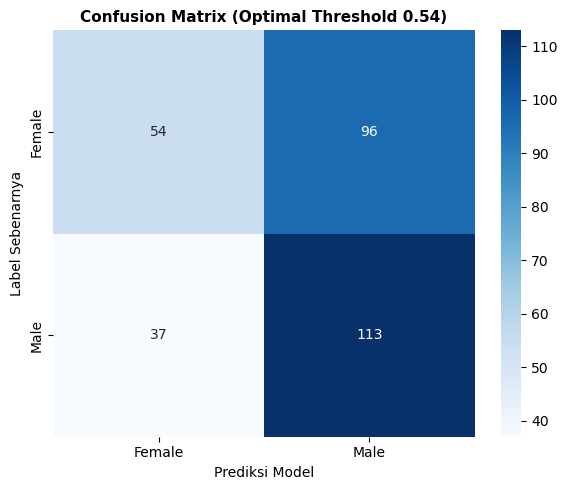

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, f1_score

y_true = []
y_probs = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_probs.extend(preds)

y_true = np.array(y_true)
y_probs = np.array(y_probs)
p_male = y_probs[:, 1]  # Probabilitas kelas Male (Jantan)

# --- KALIBRASI THRESHOLD OPTIMAL UNTUK MAKSIMALKAN F1-SCORE ---
thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = []
for t in thresholds:
    pred_t = (p_male >= t).astype(int)
    f1_scores.append(f1_score(y_true, pred_t, average="weighted"))

best_idx = np.argmax(f1_scores)
BEST_THRESHOLD = float(thresholds[best_idx])
print(f"[OPTIMASI] Threshold Optimal F1: {BEST_THRESHOLD:.3f} (F1 = {f1_scores[best_idx]:.4f})")

# Prediksi dengan default 0.5 vs Best Threshold
y_pred_default = np.argmax(y_probs, axis=1)
y_pred_optimal = (p_male >= BEST_THRESHOLD).astype(int)

print("=" * 60)
print("  HASIL EVALUASI DENGAN DEFAULT THRESHOLD (0.50)")
print("=" * 60)
print(classification_report(y_true, y_pred_default, target_names=CLASS_NAMES, digits=4))

print("=" * 60)
print(f"  HASIL EVALUASI DENGAN OPTIMAL THRESHOLD ({BEST_THRESHOLD:.2f})")
print("=" * 60)
print(classification_report(y_true, y_pred_optimal, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred_optimal)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Confusion Matrix (Optimal Threshold {BEST_THRESHOLD:.2f})", fontsize=11, fontweight="bold")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Sebenarnya")
plt.tight_layout()
plt.show()


## Langkah 6: Kuantisasi Penuh ke `model_doc_int8.tflite` (100% NPU Compatible)
Kuantisasi penuh (*Full Integer Quantization INT8*) mengonversi seluruh bobot dan aktivasi ke integer 8-bit untuk akselerasi perangkat keras NPU Arm Ethos-U55.


In [13]:
# 1. Kunci dimensi input menjadi statis [1, 160, 160, 3] agar 100% didukung NPU di Arm Vela
@tf.function(input_signature=[tf.TensorSpec(shape=[1, IMG_SIZE, IMG_SIZE, 3], dtype=tf.float32)])
def static_inference_fn(x):
    return model(x, training=False)

concrete_func = static_inference_fn.get_concrete_function()

# 2. Generator Representative Dataset dari data validasi
def representative_dataset_gen():
    sample_count = 0
    for images, _ in raw_val_ds:
        for i in range(images.shape[0]):
            single_img = tf.expand_dims(images[i], axis=0)
            single_img = tf.cast(single_img, tf.float32)
            single_img = (single_img / 127.5) - 1.0  # Skala [-1.0, 1.0]
            yield [single_img]
            sample_count += 1
            if sample_count >= 150:
                return

# 3. Konfigurasi TFLite Converter INT8 Penuh
converter = tf.lite.TFLiteConverter.from_concrete_functions([concrete_func], model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_quant_model = converter.convert()

# 4. Simpan ke model_doc_int8.tflite
tflite_model_path = MODEL_OUTPUT_DIR / "model_doc_int8.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_quant_model)

size_kb = len(tflite_quant_model) / 1024
print(f"[SUCCESS] Model INT8 tersimpan di: {tflite_model_path.resolve()}")
print(f"          Ukuran File INT8       : {size_kb:.2f} KB")

# Tulis labels_doc.txt
labels_file_path = MODEL_OUTPUT_DIR / "labels_doc.txt"
with open(labels_file_path, "w") as f:
    for i, name in enumerate(CLASS_NAMES):
        f.write(f"{i} {name}\n")
print(f"[SUCCESS] Label tersimpan di     : {labels_file_path.resolve()}")


INFO:tensorflow:Assets written to: /tmp/tmpk3uhle3j/assets


INFO:tensorflow:Assets written to: /tmp/tmpk3uhle3j/assets
2026-10-12 00:24:07.614142: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:378] Ignored output_format.
2026-10-12 00:24:07.614174: W tensorflow/compiler/mlir/lite/python/tf_tfl_flatbuffer_helpers.cc:381] Ignored drop_control_dependency.
2026-10-12 00:24:07.614621: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpk3uhle3j
2026-10-12 00:24:07.633873: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-10-12 00:24:07.633912: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: /tmp/tmpk3uhle3j
2026-10-12 00:24:07.670486: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:388] MLIR V1 optimization pass is not enabled
2026-10-12 00:24:07.682604: I tensorflow/cc/saved_model/loader.cc:233] Restoring SavedModel bundle.
2026-10-12 00:24:08.078267: I tensorflow/cc/saved_model/loader.cc:217] Running initializatio

[SUCCESS] Model INT8 tersimpan di: /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model/model_doc_int8.tflite
          Ukuran File INT8       : 616.20 KB
[SUCCESS] Label tersimpan di     : /home/nexus_is/5.Project/Groove-Vision-Ai-v2/PP2/model/labels_doc.txt


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
2026-10-12 00:24:11.644440: I tensorflow/compiler/mlir/lite/flatbuffer_export.cc:2989] Estimated count of arithmetic ops: 60.697 M  ops, equivalently 30.349 M  MACs


## Langkah 7: Evaluasi Akurasi Model `model_doc_int8.tflite`
Memverifikasi bahwa kuantisasi INT8 tidak mengalami penurunan akurasi signifikan (*accuracy drop*).


In [14]:
interpreter = tf.lite.Interpreter(model_path=str(tflite_model_path))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

in_scale, in_zero_point = input_details["quantization"]
out_scale, out_zero_point = output_details["quantization"]

print(f"Input Quantization  : Scale={in_scale:.6f}, ZeroPoint={in_zero_point}")
print(f"Output Quantization : Scale={out_scale:.6f}, ZeroPoint={out_zero_point}")

y_true_int8 = []
y_probs_int8 = []

for images, labels in raw_test_ds:
    for i in range(images.shape[0]):
        img_raw = images[i].numpy().astype(np.float32)
        img_norm = (img_raw / 127.5) - 1.0
        img_int8 = np.clip(np.round(img_norm / in_scale + in_zero_point), -128, 127).astype(np.int8)
        img_int8 = np.expand_dims(img_int8, axis=0)

        interpreter.set_tensor(input_details["index"], img_int8)
        interpreter.invoke()
        output_int8 = interpreter.get_tensor(output_details["index"])[0]
        # Dequantize output ke probabilitas float [0, 1]
        prob = (output_int8.astype(np.float32) - out_zero_point) * out_scale
        prob = np.clip(prob, 0.0, 1.0)
        # Normalisasi sum = 1 jika diperlukan
        if prob.sum() > 0:
            prob = prob / prob.sum()

        y_probs_int8.append(prob)
        y_true_int8.append(int(labels[i].numpy()))

y_true_int8 = np.array(y_true_int8)
y_probs_int8 = np.array(y_probs_int8)
y_pred_int8_optimal = (y_probs_int8[:, 1] >= BEST_THRESHOLD).astype(int)

int8_acc = np.mean(y_true_int8 == y_pred_int8_optimal) * 100.0
print("=" * 60)
print(f"  EVALUASI MODEL INT8 (Optimal Threshold: {BEST_THRESHOLD:.2f})")
print(f"  AKURASI PADA TEST SET : {int8_acc:.2f}%")
print("=" * 60)
print(classification_report(y_true_int8, y_pred_int8_optimal, target_names=CLASS_NAMES, digits=4))


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Input Quantization  : Scale=0.007843, ZeroPoint=-1
Output Quantization : Scale=0.003906, ZeroPoint=-128
  EVALUASI MODEL INT8 (Optimal Threshold: 0.54)
  AKURASI PADA TEST SET : 53.33%
              precision    recall  f1-score   support

      Female     0.5568    0.3267    0.4118       150
        Male     0.5236    0.7400    0.6133       150

    accuracy                         0.5333       300
   macro avg     0.5402    0.5333    0.5125       300
weighted avg     0.5402    0.5333    0.5125       300

